# Computer Vision Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Mahnoor Hameed Awan  |  **Reg No:** FA23-BAI-002  |  COMSATS University Islamabad, Wah Campus



#**Personal Settings (derived from my registration number FA23-BAI-002)**

In [ ]:
!pip install -q medmnist scikit-image opencv-python

In [ ]:
import re, random, warnings
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
warnings.filterwarnings("ignore")

REG_NO = "FA23-BAI-002"
digits = re.findall(r"\d", REG_NO)
last_digit = int(digits[-1])
SEED = int("".join(digits[-2:]))                 # last two digits -> 02 -> 2
HOG_CELL = (8, 8) if last_digit % 2 == 0 else (16, 16)
GRID_N = 4 if last_digit <= 4 else 6             # 4x4 = 16 keypoints, 6x6 = 36 keypoints

random.seed(SEED); np.random.seed(SEED)
print("Reg no        :", REG_NO)
print("Last digit    :", last_digit)
print("Random seed   :", SEED)
print("HOG cell size :", HOG_CELL)
print("SIFT grid     :", f"{GRID_N} x {GRID_N} ({GRID_N*GRID_N} keypoints)")

Reg no        : FA23-BAI-002
Last digit    : 2
Random seed   : 2
HOG cell size : (8, 8)
SIFT grid     : 4 x 4 (16 keypoints)


#**Q1. Data setup (3 marks)**

---







In [ ]:
from medmnist import BloodMNIST

CLASS_IDS   = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
label_map = {c: i for i, c in enumerate(CLASS_IDS)}
rng = np.random.RandomState(SEED)

def make_split(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labs = ds.imgs, ds.labels.ravel()
    X, y = [], []
    for c in CLASS_IDS:
        idx = np.where(labs == c)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)
        for i in chosen:
            g = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)                 # grayscale
            g = cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR) # 128 x 128
            X.append(g); y.append(label_map[c])
    return np.array(X, dtype=np.uint8), np.array(y)

X_train, y_train = make_split("train", 100)
X_val,   y_val   = make_split("val",   30)
X_test,  y_test  = make_split("test",  30)

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    counts = {CLASS_NAMES[k]: int(v) for k, v in zip(*np.unique(y, return_counts=True))}
    print(f"{name:5s} X shape: {X.shape}, y shape: {y.shape}, dtype: {X.dtype}, class counts: {counts}")

100%|██████████| 156M/156M [01:13<00:00, 2.13MB/s]


train X shape: (400, 128, 128), y shape: (400,), dtype: uint8, class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   X shape: (120, 128, 128), y shape: (120,), dtype: uint8, class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  X shape: (120, 128, 128), y shape: (120,), dtype: uint8, class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


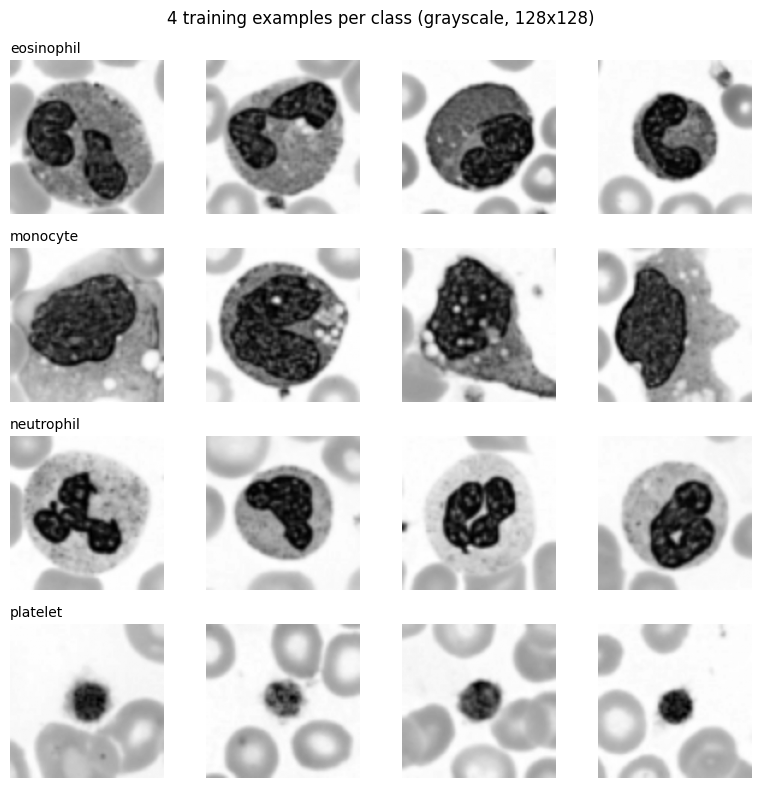

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_train == r)[0][:4]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train[i], cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(cname, loc="left", fontsize=10)
plt.suptitle("4 training examples per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

# **Q2. HOG + SVM (6 marks)**

---



##**Q2(a) Feature length: hand calculation**
Settings: image 128 x 128, cell = 8 x 8, 9 orientations, block = 2 x 2 cells, block stride = 1 cell.

- Cells per side = 128 / 8 = **16**, so 16 x 16 = 256 cells.
- Blocks per side = 16 - 2 + 1 = **15**, so 15 x 15 = **225 blocks**.
- Values per block = 2 x 2 cells x 9 orientations = **36**.
- Total HOG length = 225 x 36 = **8100**.

(General formula: (128/cell - 1)^2 x 2 x 2 x 9.) The code below must print the same number.

In [ ]:
def hog_feat(img, vis=False):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
               block_norm="L2-Hys", visualize=vis, feature_vector=True)

def extract_hog(X):
    return np.array([hog_feat(im) for im in X])

H_train, H_val, H_test = extract_hog(X_train), extract_hog(X_val), extract_hog(X_test)
cells_side = 128 // HOG_CELL[0]
expected = (cells_side - 1) ** 2 * 2 * 2 * 9
print("HOG feature matrix (train):", H_train.shape)
print("HOG feature length:", H_train.shape[1], "| hand-calculated:", expected, "| match:", H_train.shape[1] == expected)

HOG feature matrix (train): (400, 8100)
HOG feature length: 8100 | hand-calculated: 8100 | match: True


##**Q2(b) HOG pictures (one image per class)**

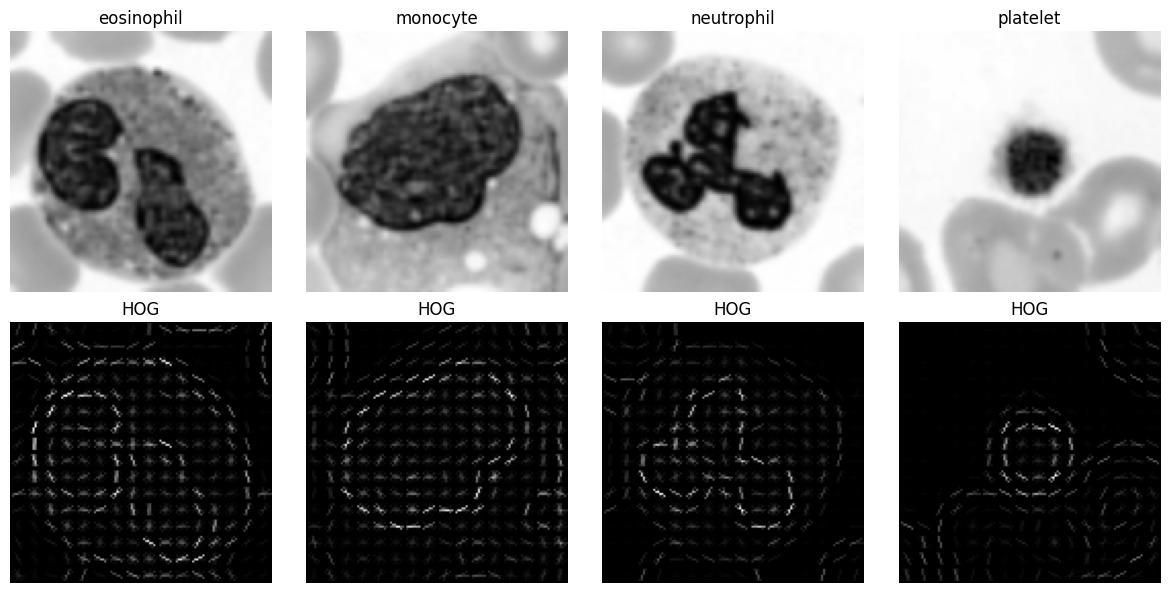

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for r, cname in enumerate(CLASS_NAMES):
    i = np.where(y_train == r)[0][0]
    _, hog_img = hog_feat(X_train[i], vis=True)
    axes[0, r].imshow(X_train[i], cmap="gray"); axes[0, r].set_title(cname); axes[0, r].axis("off")
    axes[1, r].imshow(hog_img, cmap="gray");    axes[1, r].set_title("HOG"); axes[1, r].axis("off")
plt.tight_layout(); plt.show()

##**Q2(c) Train SVM (choose C on validation)**

[HOG+SVM] C=0.1  val accuracy = 0.7833
[HOG+SVM] C=1    val accuracy = 0.7833
[HOG+SVM] C=10   val accuracy = 0.7833
[HOG+SVM] Best C = 0.1 (val acc 0.7833)
HOG + SVM: validation accuracy = 0.7833, macro-F1 = 0.7837
Confusion matrix (rows = true, cols = predicted):
 [[19  8  3  0]
 [ 5 23  2  0]
 [ 4  4 22  0]
 [ 0  0  0 30]]


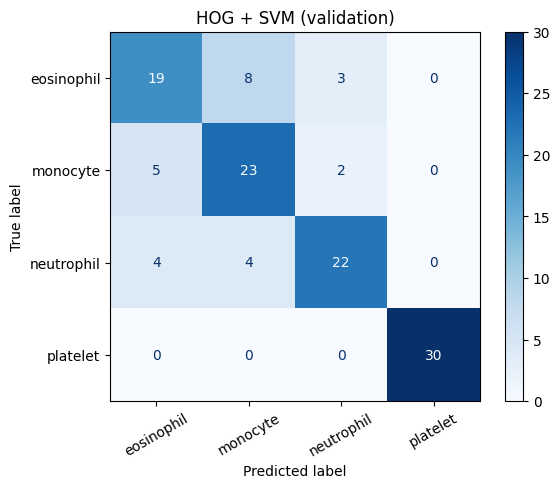

In [ ]:
def tune_svm(Xtr, ytr, Xva, yva, scale=False, name="model"):
    best = {"acc": -1}
    for C in [0.1, 1, 10]:
        clf = LinearSVC(C=C, max_iter=20000, random_state=SEED)
        model = make_pipeline(StandardScaler(), clf) if scale else clf
        model.fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        print(f"[{name}] C={C:<4} val accuracy = {acc:.4f}")
        if acc > best["acc"]:
            best = {"acc": acc, "C": C, "model": model}
    print(f"[{name}] Best C = {best['C']} (val acc {best['acc']:.4f})")
    return best["model"], best["C"]

def report(model, X, y, name):
    pred = model.predict(X)
    acc = accuracy_score(y, pred); f1 = f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred)
    print(f"{name}: validation accuracy = {acc:.4f}, macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):\n", cm)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(name + " (validation)"); plt.show()
    return acc, f1, cm

hog_model, hog_C = tune_svm(H_train, y_train, H_val, y_val, scale=False, name="HOG+SVM")
hog_val_acc, hog_val_f1, hog_cm = report(hog_model, H_val, y_val, "HOG + SVM")

**Result (HOG + SVM):** C = 0.1, 1 and 10 all gave 0.7833 on validation, so I kept the smallest C = 0.1. Validation accuracy is 0.7833 and macro-F1 is 0.7837. Platelets were perfect (30/30), and most mistakes were between eosinophil and monocyte.

#**Q3. SIFT + SVM (7 marks)**

---



##**Q3(a) Normal SIFT detection on training images**

Average keypoints/image: 70.10
Minimum keypoints/image: 9
Maximum keypoints/image: 179
Images with zero keypoints: 0 of 400


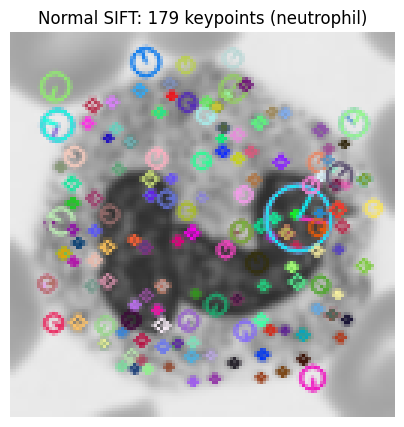

In [ ]:
sift = cv2.SIFT_create()
kp_counts, first_kp_img = [], None
for i, im in enumerate(X_train):
    kps, desc = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)
print(f"Average keypoints/image: {kp_counts.mean():.2f}")
print(f"Minimum keypoints/image: {kp_counts.min()}")
print(f"Maximum keypoints/image: {kp_counts.max()}")
print(f"Images with zero keypoints: {(kp_counts == 0).sum()} of {len(kp_counts)}")

i = int(np.argmax(kp_counts))   # image with most keypoints, for a clear picture
kps, _ = sift.detectAndCompute(X_train[i], None)
vis = cv2.drawKeypoints(X_train[i], kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off")
plt.title(f"Normal SIFT: {len(kps)} keypoints ({CLASS_NAMES[y_train[i]]})"); plt.show()

**Why a different number of keypoints per image is a problem for an SVM:** every keypoint gives a 128-number descriptor, so an image with 9 keypoints gives a much shorter vector than an image with 179 keypoints, and an SVM needs every image to have the same number of features.

##**Q3(b) Fixed grid of keypoints**


Grid = 4 x 4 = 16 keypoints on the 128 x 128 image (centres of equal cells, step = 128/4 = 32), keypoint size = 32.
Feature length = grid points x 128 = 16 x 128 = **2048**.

SIFT feature matrix (train): (400, 2048)
SIFT feature length: 2048 | hand-calculated: 2048 | match: True


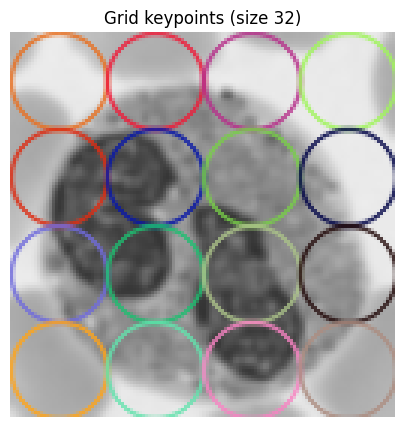

In [ ]:
def grid_keypoints(n=GRID_N, size=128, kp_size=32):
    step = size / n
    centres = [step / 2 + k * step for k in range(n)]
    return [cv2.KeyPoint(float(x), float(y), kp_size) for y in centres for x in centres]

sift_grid = cv2.SIFT_create()

def sift_feat(img):
    kps = grid_keypoints()
    kps, desc = sift_grid.compute(img, kps)
    out = np.zeros(GRID_N * GRID_N * 128, dtype=np.float32)   # safe if a point is dropped
    if desc is not None:
        flat = desc.flatten()
        out[:len(flat)] = flat
    return out

def extract_sift(X):
    return np.array([sift_feat(im) for im in X])

S_train, S_val, S_test = extract_sift(X_train), extract_sift(X_val), extract_sift(X_test)
print("SIFT feature matrix (train):", S_train.shape)
print("SIFT feature length:", S_train.shape[1], "| hand-calculated:", GRID_N * GRID_N * 128,
      "| match:", S_train.shape[1] == GRID_N * GRID_N * 128)

# draw the grid keypoints on one image
vis = cv2.drawKeypoints(X_train[0], grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off"); plt.title("Grid keypoints (size 32)"); plt.show()

##**Q3(c) Train SVM (choose C on validation)**

[SIFT+SVM] C=0.1  val accuracy = 0.7833
[SIFT+SVM] C=1    val accuracy = 0.7917
[SIFT+SVM] C=10   val accuracy = 0.7917
[SIFT+SVM] Best C = 1 (val acc 0.7917)
SIFT + SVM: validation accuracy = 0.7917, macro-F1 = 0.7889
Confusion matrix (rows = true, cols = predicted):
 [[17  6  7  0]
 [ 5 24  1  0]
 [ 4  2 24  0]
 [ 0  0  0 30]]


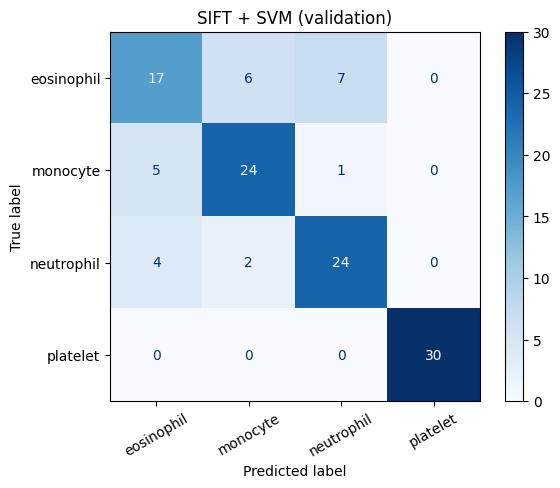

In [ ]:
sift_model, sift_C = tune_svm(S_train, y_train, S_val, y_val, scale=True, name="SIFT+SVM")
sift_val_acc, sift_val_f1, sift_cm = report(sift_model, S_val, y_val, "SIFT + SVM")

**Result (SIFT + SVM):** C = 1 and C = 10 tied at 0.7917, so I kept the smaller one, C = 1. Validation accuracy is 0.7917 and macro-F1 is 0.7889. Platelets were again perfect (30/30), and eosinophil was often confused with monocyte and neutrophil.

*Note: SIFT descriptors have large values, so a StandardScaler is placed before LinearSVC (it is part of the frozen model and fitted on training data only).*

#**Q4. Robustness (6 marks)**

---



##**Q4(a) Prediction (written BEFORE running the test evaluation)**


**Rotation:** I think **HOG** will lose more accuracy. HOG uses a fixed layout of 8 x 8 cells with edge-direction histograms, so a 20 degree rotation moves edges into different direction bins and different cells. SIFT on a grid is also not rotation invariant, but each 32 x 32 descriptor is smoothed and Gaussian-weighted, so it changes more gently.

**Noise:** I think **HOG** will lose more accuracy. HOG works on raw pixel gradients, and noise creates many fake edges. SIFT blurs the image with a Gaussian first, which removes much of the noise.

##**Q4(b) Evaluate frozen models on the test set (clean, rotated 20 deg, noisy sigma = 0.05)**

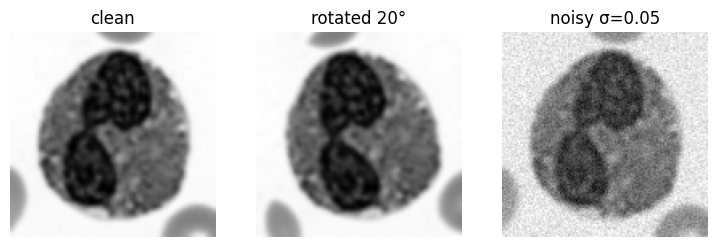

,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,0.7000,0.6583,0.6083
SIFT + SVM,0.7083,0.7417,0.6833


,Drop under rotation,Drop under noise
Model,,
HOG + SVM,0.0417,0.0917
SIFT + SVM,-0.0333,0.0250


Larger rotation drop: HOG + SVM
Larger noise drop   : HOG + SVM


In [ ]:
def rotate(img, angle=20):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def add_noise(imgs, sigma=0.05):
    r = np.random.RandomState(SEED)
    x = imgs.astype(np.float32) / 255.0                  # scale to 0..1
    x = np.clip(x + r.normal(0, sigma, x.shape), 0, 1)
    return (x * 255).round().astype(np.uint8)           # back to uint8 (SIFT needs uint8)

X_test_rot   = np.array([rotate(im, 20) for im in X_test])
X_test_noisy = add_noise(X_test, 0.05)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["clean", "rotated 20°", "noisy σ=0.05"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

# models are frozen: no more fitting below. Change is applied BEFORE feature extraction.
def acc_on(model, extractor, X):
    return accuracy_score(y_test, model.predict(extractor(X)))

rows = []
for name, model, ext in [("HOG + SVM", hog_model, extract_hog), ("SIFT + SVM", sift_model, extract_sift)]:
    rows.append({"Model": name,
                 "Clean accuracy":   acc_on(model, ext, X_test),
                 "Rotated accuracy": acc_on(model, ext, X_test_rot),
                 "Noisy accuracy":   acc_on(model, ext, X_test_noisy)})
results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

drops = pd.DataFrame({"Drop under rotation": results["Clean accuracy"] - results["Rotated accuracy"],
                      "Drop under noise":    results["Clean accuracy"] - results["Noisy accuracy"]})
display(drops.round(4))
print("Larger rotation drop:", drops["Drop under rotation"].idxmax())
print("Larger noise drop   :", drops["Drop under noise"].idxmax())

**Robustness table (from the output above):**

| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---|---|---|
| HOG + SVM | 0.7000 | 0.6583 | 0.6083 |
| SIFT + SVM | 0.7083 | 0.7417 | 0.6833 |

##**Q4(c) Was my prediction correct? (3 sentences)**
Yes, my prediction was correct for both cases. Under rotation HOG dropped from 0.7000 to 0.6583 (a drop of 0.0417), while SIFT went up from 0.7083 to 0.7417; under noise HOG dropped by 0.0917 (0.7000 to 0.6083) and SIFT dropped by only 0.0250 (0.7083 to 0.6833). So SIFT is more reliable than HOG here, and its small rise under rotation is most likely chance, because with only 120 test images a few lucky predictions change the accuracy by several percent.

#**Q5. Short answers and AI log (3 marks)**

---



**(a) Why does HOG use block normalisation?**
Lighting and contrast change how strong the gradients are, so the same cell can give very different numbers in a bright image and a dark image. Block normalisation scales each 2 x 2 group of cells by its own strength, so the feature describes the edge pattern instead of the brightness. Because the blocks overlap, each cell is normalised several times, which makes the feature more stable.

**(b) Why is it wrong to choose C using the test set?**
If I pick C because it gives the best test score, the test set has helped to build the model, so it is no longer unseen data. The final test accuracy would then look better than it really is on new images. So C must be chosen on the validation set, and the test set is used only once at the end.

In [ ]:
def top_confusion(cm):
    c = cm.copy().astype(int); np.fill_diagonal(c, 0)
    # symmetric: confusions A->B plus B->A
    best, pair = -1, None
    for a in range(4):
        for b in range(a + 1, 4):
            s = c[a, b] + c[b, a]
            if s > best: best, pair = s, (a, b)
    return CLASS_NAMES[pair[0]], CLASS_NAMES[pair[1]], best

for name, cm in [("HOG + SVM", hog_cm), ("SIFT + SVM", sift_cm)]:
    a, b, n = top_confusion(cm)
    print(f"{name}: most confused pair = {a} <-> {b} ({n} mistakes on validation)")

HOG + SVM: most confused pair = eosinophil <-> monocyte (13 mistakes on validation)
SIFT + SVM: most confused pair = eosinophil <-> monocyte (11 mistakes on validation)


**Which two classes did the models confuse most, and why might grayscale make it harder?**
Eosinophil and monocyte were confused most. HOG made 13 mistakes between them (8 eosinophil predicted as monocyte and 5 monocyte predicted as eosinophil), and SIFT made 11 (6 and 5). Eosinophils are mainly recognised by their bright red-orange granules, and grayscale removes this colour, so they look much more like the other white cells. HOG and SIFT then have only shape and texture to use, and these cells have similar shapes.

### AI log
| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| "Solve the HOG vs SIFT BloodMNIST lab mid exam and give a Colab notebook" | Set seed 2, HOG cell 8x8 and 4x4 SIFT grid from my reg no. FA23-BAI-002 | Printed split shapes and class counts (400/120/120, 100/30/30 per class); matched HOG length 8100 and SIFT length 2048 with my hand calculation; looked at the HOG pictures and keypoint images; confirmed C was chosen on validation only |
| "Give answers to the questions using my notebook outputs in simple words" | Wrote the answers for Q3, Q4 and Q5 in my own words and replaced the blanks | Compared every number with the printed accuracy table and confusion matrices |